# DWD-Wetterdaten Berlin 2025: Explorative Datenanalyse

Dieses Notebook untersucht tägliche Temperatur-, Niederschlags- und Sonnenscheindaten der DWD-Station **Berlin-Tempelhof (00433)** für das Kalenderjahr 2025. Die Rohdaten werden aus dem frei zugänglichen DWD-CDC-Archiv bezogen und die Ergebnisse ausschließlich aus den tatsächlich geladenen Messwerten berechnet.

## Im Browser öffnen

Im VS-Code-Terminal im Projektordner `jupyter lab --no-browser --ip=0.0.0.0 --port=8888` ausführen und den angezeigten Token-Link im Browser öffnen. In einer Dev-Container-Umgebung den Port 8888 gegebenenfalls über die VS-Code-Ports-Ansicht weiterleiten. Anschließend die Zellen der Reihe nach ausführen oder **Restart & Run All** verwenden.

Die Datei lässt sich in Jupyter über **File → Save Notebook** als `.ipynb` speichern und über **File → Save and Export Notebook As** z. B. als HTML exportieren.

## 1. Benötigte Bibliotheken

Verwendet werden `pandas`, `numpy` und `matplotlib` für Datenaufbereitung und Grafiken, `scikit-learn` für die Modellvergleiche sowie Python-Standardbibliotheken für HTTP-Abruf und ZIP-Dateien. Falls `scikit-learn` im Notebook-Kernel fehlt, einmalig `%pip install scikit-learn` ausführen.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError, HTTPError
from html.parser import HTMLParser
from zipfile import ZipFile
from io import BytesIO
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, mean_absolute_error, mean_squared_error, precision_score, r2_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

STATION_ID = "00433"
STATION_NAME = "Berlin-Tempelhof"
YEAR = 2025
BASE_URL = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl"
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)


## Datenquelle und Messgrößen

Quelle ist der DWD Climate Data Center (CDC), tägliche Stationsmessungen (`kl`). Für die gesamte Stationshistorie und die jeweils aktuellen Daten werden passende ZIP-Archive aus den DWD-Verzeichnissen geladen und anhand des Datums zusammengeführt. Lokale ZIP-Dateien bleiben im Ordner `data/` erhalten.

Untersucht werden `TMK` (Tagesmittel), `TXK` (Tagesmaximum), `TNK` (Tagesminimum) in °C, `RSK` (Tagessumme Niederschlag) in mm und `SDK` (Sonnenscheindauer) in Stunden. Der Wert `-999` gilt beim DWD als fehlend. Die Messung an einer Station ist nicht repräsentativ für jeden Berliner Stadtteil.

In [2]:
class DWDLinkParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag == "a":
            href = dict(attrs).get("href")
            if href:
                self.links.append(href)


def load_station_archives():
    """Lädt verfügbare historische und aktuelle Stationsarchive aus dem DWD-CDC."""
    frames = []
    archive_names = []

    for period in ("historical", "recent"):
        folder_url = f"{BASE_URL}/{period}/"
        try:
            with urlopen(folder_url, timeout=30) as response:
                parser = DWDLinkParser()
                parser.feed(response.read().decode("utf-8", errors="replace"))
        except (HTTPError, URLError, TimeoutError) as exc:
            print(f"DWD-Verzeichnis {period!r} nicht erreichbar: {exc}")
            continue

        candidates = sorted({
            link for link in parser.links
            if link.startswith(f"tageswerte_KL_{STATION_ID}_") and link.endswith(".zip")
        })
        for archive_name in candidates:
            archive_path = DATA_DIR / archive_name
            if not archive_path.exists():
                archive_url = f"{folder_url}{archive_name}"
                try:
                    with urlopen(archive_url, timeout=60) as response:
                        archive_path.write_bytes(response.read())
                except (HTTPError, URLError, TimeoutError) as exc:
                    print(f"Archiv {archive_name} konnte nicht geladen werden: {exc}")
                    continue

            try:
                with ZipFile(archive_path) as archive:
                    text_files = [
                        name for name in archive.namelist()
                        if name.lower().startswith("produkt_klima_tag_") and name.lower().endswith(".txt")
                    ]
                    for text_name in text_files:
                        with archive.open(text_name) as file:
                            frame = pd.read_csv(
                                file,
                                sep=";",
                                encoding="latin-1",
                                na_values=[-999, "-999", ""],
                                low_memory=False,
                            )
                        frame = frame.drop(columns=["eor"], errors="ignore")
                        frames.append(frame)
                        archive_names.append(archive_name)
            except (OSError, ValueError, KeyError) as exc:
                print(f"Archiv {archive_name} ist nicht lesbar: {exc}")

    if not frames:
        raise RuntimeError(
            "Keine Stationsdaten erhalten. Bitte Netzwerkverbindung und DWD-Open-Data-URL prüfen. "
            "Die Quelle ist https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/"
        )

    data = pd.concat(frames, ignore_index=True)
    data.columns = data.columns.str.strip()
    data = data.drop_duplicates(subset="MESS_DATUM", keep="last")
    data["MESS_DATUM"] = pd.to_datetime(data["MESS_DATUM"].astype(str), format="%Y%m%d", errors="coerce")
    data = data.dropna(subset=["MESS_DATUM"]).sort_values("MESS_DATUM").set_index("MESS_DATUM")

    for column in ("TMK", "TXK", "TNK", "RSK", "SDK"):
        if column in data:
            data[column] = pd.to_numeric(data[column], errors="coerce")

    return data, sorted(set(archive_names))


try:
    station_data, used_archives = load_station_archives()
except Exception as error:
    raise RuntimeError(f"DWD-Datenabruf fehlgeschlagen: {error}") from error

print(f"Station: {STATION_NAME} ({STATION_ID})")
print(f"Rohdaten: {len(station_data):,} Tage, {station_data.index.min().date()} bis {station_data.index.max().date()}")
print("Verwendete Archive:", ", ".join(used_archives))
display(station_data.tail())

Station: Berlin-Tempelhof (00433)
Rohdaten: 28,795 Tage, 1948-01-01 bis 2026-11-01
Verwendete Archive: tageswerte_KL_00433_19480101_20251231_hist.zip, tageswerte_KL_00433_akt.zip


,STATIONS_ID,QN_3,FX,FM,QN_4,RSK,RSKF,SDK,SHK_TAG,NM,VPM,PM,TMK,UPM,TXK,TNK,TGK
MESS_DATUM,,,,,,,,,,,,,,,,,
2026-10-28,433,1.0,7.6,2.7,1,0.7,6.0,NaN,0.0,5.7,10.7,1017.76,9.2,91.83,12.5,3.6,1.0
2026-10-29,433,1.0,6.2,1.8,1,0.0,6.0,NaN,0.0,4.6,10.4,1023.85,8.5,93.46,12.6,3.6,-0.4
2026-10-30,433,1.0,6.1,2.2,1,0.0,6.0,NaN,0.0,8.0,10.6,1026.08,8.2,97.13,9.5,6.7,7.4
2026-10-31,433,1.0,8.2,3.7,1,0.0,6.0,NaN,0.0,6.8,10.1,1025.31,9.2,86.42,11.7,5.6,3.1
2026-11-01,433,1.0,5.5,2.1,1,0.0,0.0,NaN,0.0,7.9,9.0,1026.20,8.3,82.21,10.7,6.8,5.4


## Datenqualität und Jahreskennzahlen

Der Sollumfang beträgt 365 Kalendertage. Neben tatsächlich fehlenden Datumseinträgen wird je Messgröße die Anzahl vorhandener Werte ausgewiesen. Regen- und Sonnenscheinsummen berücksichtigen nur beobachtete Tage; ihre Abdeckung steht deshalb direkt daneben.

In [3]:
expected_dates = pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-31", freq="D")
year_data = station_data.loc[f"{YEAR}-01-01":f"{YEAR}-12-31"].reindex(expected_dates)
year_data.index.name = "Datum"

variables = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "RSK": "Niederschlag (mm)",
    "SDK": "Sonnenschein (h)",
}
missing_columns = [column for column in variables if column not in year_data.columns]
if missing_columns:
    raise KeyError(f"Diese erwarteten DWD-Spalten fehlen: {missing_columns}")

missing_dates = expected_dates.difference(station_data.index)
coverage_rows = []
for column, label in variables.items():
    observed = int(year_data[column].notna().sum())
    coverage_rows.append({
        "Messgröße": label,
        "Messwerte": f"{observed}/{len(expected_dates)}",
        "Abdeckung (%)": round(100 * observed / len(expected_dates), 1),
        "Fehlend": len(expected_dates) - observed,
    })

print(f"Kalenderjahr {YEAR}: {len(year_data)} Solltage")
print(f"Fehlende Datumszeilen: {len(missing_dates)}")
if len(missing_dates):
    print("Fehlende Tage:", ", ".join(date.strftime("%d.%m.%Y") for date in missing_dates))
display(pd.DataFrame(coverage_rows).set_index("Messgröße"))

def value_on_extreme(series, kind):
    valid = series.dropna()
    if valid.empty:
        return "keine Daten"
    date = valid.idxmax() if kind == "max" else valid.idxmin()
    return f"{valid.loc[date]:.1f} °C am {date:%d.%m.%Y}"

rain = year_data["RSK"]
sunshine = year_data["SDK"]
annual_metrics = pd.DataFrame({
    "Kennzahl": [
        "Jahresmittel Tagesmitteltemperatur",
        "Höchstes Tagesmaximum",
        "Niedrigstes Tagesminimum",
        "Niederschlagssumme",
        "Regentage (mindestens 1 mm)",
        "Stärkster Tagesniederschlag",
        "Sonnenscheinsumme",
    ],
    "Wert": [
        f"{year_data['TMK'].mean():.1f} °C" if year_data["TMK"].notna().any() else "keine Daten",
        value_on_extreme(year_data["TXK"], "max"),
        value_on_extreme(year_data["TNK"], "min"),
        f"{rain.sum(min_count=1):.1f} mm" if rain.notna().any() else "keine Daten",
        f"{int((rain >= 1).sum())} Tage" if rain.notna().any() else "keine Daten",
        f"{rain.max():.1f} mm am {rain.idxmax():%d.%m.%Y}" if rain.notna().any() else "keine Daten",
        f"{sunshine.sum(min_count=1):.1f} h" if sunshine.notna().any() else "keine Daten",
    ],
})
display(annual_metrics.set_index("Kennzahl"))

monthly = year_data.resample("MS").agg({"TMK": "mean", "TNK": "min", "TXK": "max", "RSK": lambda values: values.sum(min_count=1), "SDK": lambda values: values.sum(min_count=1)})
monthly.index = monthly.index.month
monthly.index.name = "Monat"
monthly

Kalenderjahr 2025: 365 Solltage
Fehlende Datumszeilen: 0


,Messwerte,Abdeckung (%),Fehlend
Messgröße,,,
Tagesmitteltemperatur (°C),365/365,100.0,0
Tagesmaximum (°C),365/365,100.0,0
Tagesminimum (°C),365/365,100.0,0
Niederschlag (mm),365/365,100.0,0
Sonnenschein (h),0/365,0.0,365


,Wert
Kennzahl,
Jahresmittel Tagesmitteltemperatur,11.1 °C
Höchstes Tagesmaximum,37.6 °C am 02.07.2025
Niedrigstes Tagesminimum,-11.6 °C am 18.02.2025
Niederschlagssumme,458.5 mm
Regentage (mindestens 1 mm),97 Tage
Stärkster Tagesniederschlag,24.7 mm am 12.07.2025
Sonnenscheinsumme,keine Daten


,TMK,TNK,TXK,RSK,SDK
Monat,,,,,
1,3.074194,-4.7,14.6,54.9,NaN
2,1.703571,-11.6,15.4,16.0,NaN
3,7.106452,-4.5,19.1,8.7,NaN
4,12.166667,-0.8,26.7,13.7,NaN
5,13.793548,0.9,29.0,33.8,NaN
6,19.726667,9.4,34.7,34.6,NaN
7,19.819355,12.7,37.6,127.4,NaN
8,19.135484,8.9,34.5,32.6,NaN
9,16.193333,4.7,29.5,35.1,NaN


## Monatsverteilungen der Tagesmitteltemperatur

Der Boxplot vergleicht die täglichen Mitteltemperaturen innerhalb der zwölf Monate. Die Box umfasst das 25. bis 75. Perzentil, die Linie darin markiert den Median, die Raute den arithmetischen Mittelwert. Whisker reichen bis zum letzten Wert innerhalb von 1,5 Interquartilsabständen; darüber hinausgehende Beobachtungen werden einzeln als Ausreißer gezeigt. Die Fallzahl je Monat ist in der Achsenbeschriftung angegeben.

,Tage (n),Mittelwert (°C),Median (°C),Q1 (°C),Q3 (°C),IQR (°C)
Monat,,,,,,
Jan,31,3.07,2.10,0.40,5.90,5.50
Feb,28,1.70,1.20,-0.90,3.95,4.85
Mär,31,7.11,7.50,5.15,9.20,4.05
Apr,30,12.17,11.75,9.45,14.50,5.05
Mai,31,13.79,13.50,11.30,16.45,5.15
Jun,30,19.73,19.30,18.20,21.88,3.67
Jul,31,19.82,18.90,17.65,21.10,3.45
Aug,31,19.14,18.70,17.40,20.20,2.80
Sep,30,16.19,16.50,13.30,18.80,5.50


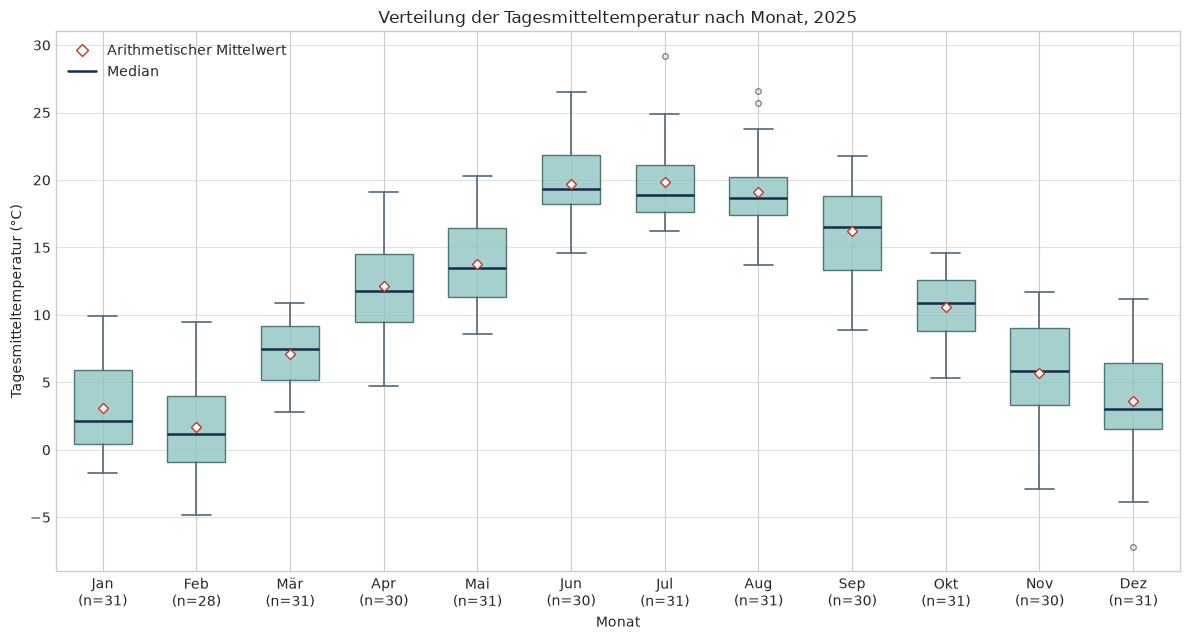

**Kurzinterpretation:** Der höchste Monatsmedian liegt im **Jun** (19.3 °C). Die größte Streuung der mittleren 50 % der Tageswerte zeigt **Nov** (IQR 5.7 °C). Einzelne Punkte außerhalb der Whisker sind nach der 1,5-IQR-Regel statistische Ausreißer, nicht automatisch Messfehler.

In [4]:
month_labels = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
temperature_by_month = year_data["TMK"].groupby(year_data.index.month)
month_summary = pd.DataFrame({
    "Tage (n)": temperature_by_month.count(),
    "Mittelwert (°C)": temperature_by_month.mean(),
    "Median (°C)": temperature_by_month.median(),
    "Q1 (°C)": temperature_by_month.quantile(0.25),
    "Q3 (°C)": temperature_by_month.quantile(0.75),
})
month_summary["IQR (°C)"] = month_summary["Q3 (°C)"] - month_summary["Q1 (°C)"]
month_summary.index = [month_labels[month - 1] for month in month_summary.index]
month_summary.index.name = "Monat"
display(month_summary.round(2))

boxplot_values = [
    year_data.loc[year_data.index.month == month, "TMK"].dropna().to_numpy()
    for month in range(1, 13)
]
fig, ax = plt.subplots(figsize=(12, 6.5))
boxplot = ax.boxplot(
    boxplot_values,
    positions=np.arange(1, 13),
    widths=0.62,
    whis=1.5,
    showmeans=True,
    showfliers=True,
    patch_artist=True,
    medianprops={"color": "#172b4d", "linewidth": 1.8},
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "#c0392b", "markersize": 5},
    flierprops={"marker": "o", "markerfacecolor": "none", "markeredgecolor": "#555555", "markersize": 4, "alpha": 0.7},
    whiskerprops={"color": "#536878", "linewidth": 1.2},
    capprops={"color": "#536878", "linewidth": 1.2},
)
for box in boxplot["boxes"]:
    box.set_facecolor("#8fc5c1")
    box.set_edgecolor("#315b59")
    box.set_alpha(0.8)

ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels([
    f"{month_labels[month - 1]}\n(n={len(boxplot_values[month - 1])})"
    for month in range(1, 13)
])
ax.set_title(f"Verteilung der Tagesmitteltemperatur nach Monat, {YEAR}")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.grid(axis="y", color="#cbd5d8", alpha=0.65, linewidth=0.8)
ax.set_axisbelow(True)
ax.plot([], [], marker="D", linestyle="none", markerfacecolor="white", markeredgecolor="#c0392b", label="Arithmetischer Mittelwert")
ax.plot([], [], color="#172b4d", linewidth=1.8, label="Median")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

warmest_median_month = month_summary["Median (°C)"].idxmax()
widest_iqr_month = month_summary["IQR (°C)"].idxmax()
display(Markdown(
    f"**Kurzinterpretation:** Der höchste Monatsmedian liegt im **{warmest_median_month}** "
    f"({month_summary.loc[warmest_median_month, 'Median (°C)']:.1f} °C). Die größte Streuung der mittleren 50 % "
    f"der Tageswerte zeigt **{widest_iqr_month}** (IQR {month_summary.loc[widest_iqr_month, 'IQR (°C)']:.1f} °C). "
    "Einzelne Punkte außerhalb der Whisker sind nach der 1,5-IQR-Regel statistische Ausreißer, nicht automatisch Messfehler."
))

## Korrelationen der fünf Wettermerkmale

Für 2025 werden Tagesmittel-, Höchst- und Tiefsttemperatur, Niederschlag sowie maximale Windböe untersucht. Sonnenschein ist nicht enthalten, da die DWD-Reihe für diese Station 2025 keine gültigen SDK-Werte enthält. Berechnet wird Pearson-$r$ auf paarweise vollständigen Tageswerten; die Fallzahlen stehen separat dabei. Bei Niederschlag sind viele Nullwerte und einzelne Starkregenereignisse zu beachten, daher ist die Korrelation nur ein Hinweis auf lineare Zusammenhänge und keine Ursache-Wirkungs-Aussage.

Pearson-Korrelationen (paarweise vollständige Tageswerte):


,Tagesmitteltemperatur (°C),Tagesmaximum (°C),Tagesminimum (°C),Niederschlag (mm),Maximale Windböe (m/s)
Tagesmitteltemperatur (°C),1.00,0.98,0.95,0.11,0.24
Tagesmaximum (°C),0.98,1.00,0.87,0.04,0.22
Tagesminimum (°C),0.95,0.87,1.00,0.21,0.28
Niederschlag (mm),0.11,0.04,0.21,1.00,0.16
Maximale Windböe (m/s),0.24,0.22,0.28,0.16,1.00


Anzahl verwendeter Tagespaare:


,Tagesmitteltemperatur (°C),Tagesmaximum (°C),Tagesminimum (°C),Niederschlag (mm),Maximale Windböe (m/s)
Tagesmitteltemperatur (°C),365,365,365,365,365
Tagesmaximum (°C),365,365,365,365,365
Tagesminimum (°C),365,365,365,365,365
Niederschlag (mm),365,365,365,365,365
Maximale Windböe (m/s),365,365,365,365,365


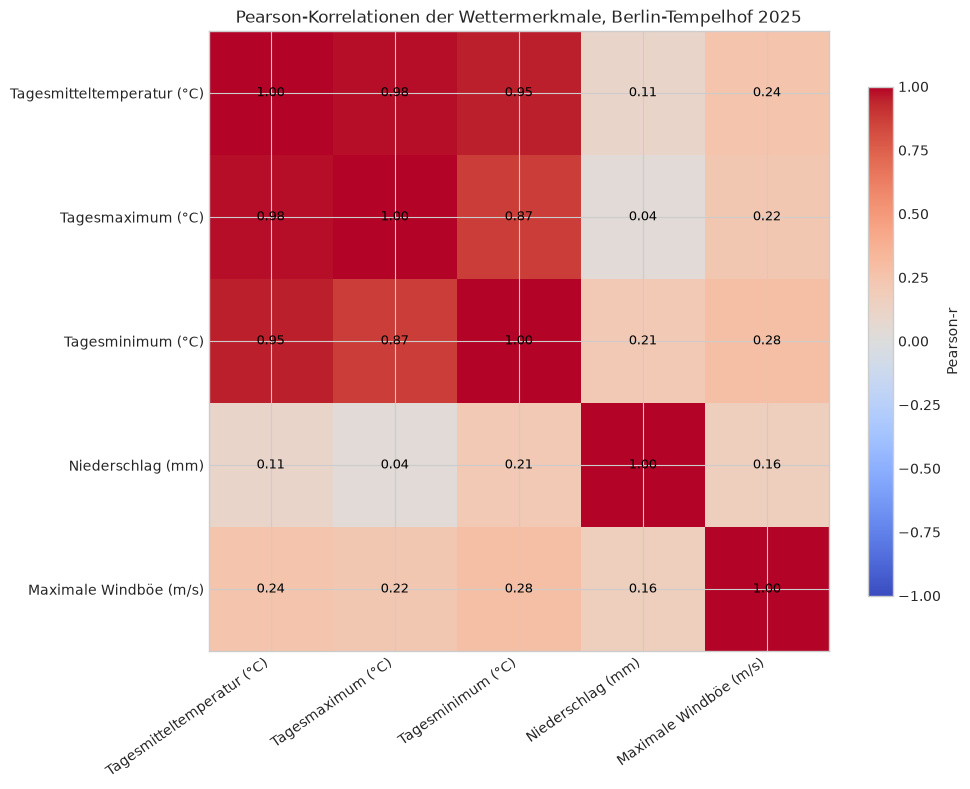

## Auswertung der Korrelationen

- **Tagesmitteltemperatur (°C) ↔ Tagesmaximum (°C):** starker positiver Zusammenhang ($r=0.98$, $n=365$ Tagespaare).
- **Tagesmitteltemperatur (°C) ↔ Tagesminimum (°C):** starker positiver Zusammenhang ($r=0.95$, $n=365$ Tagespaare).
- **Tagesmaximum (°C) ↔ Tagesminimum (°C):** starker positiver Zusammenhang ($r=0.87$, $n=365$ Tagespaare).
- **Tagesminimum (°C) ↔ Maximale Windböe (m/s):** schwacher positiver Zusammenhang ($r=0.28$, $n=365$ Tagespaare).
- **Tagesmitteltemperatur (°C) ↔ Maximale Windböe (m/s):** schwacher positiver Zusammenhang ($r=0.24$, $n=365$ Tagespaare).

Pearson-$r$ beschreibt hier lineare Mitbewegungen der täglichen Stationswerte. Besonders Temperaturmerkmale sind teilweise definitionsgemäß eng verwandt; Niederschlag und Windböen können durch einzelne Ereignisse geprägt sein. Korrelationen erlauben keine kausalen Schlüsse.

In [5]:
correlation_features = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "RSK": "Niederschlag (mm)",
    "FX": "Maximale Windböe (m/s)",
}
missing_correlation_features = [name for name in correlation_features if name not in year_data.columns]
if missing_correlation_features:
    raise KeyError(f"Für die Korrelationsanalyse fehlen DWD-Spalten: {missing_correlation_features}")

correlation_data = year_data[list(correlation_features)].apply(pd.to_numeric, errors="coerce")
correlation_data = correlation_data.rename(columns=correlation_features)
correlation_matrix = correlation_data.corr(method="pearson", min_periods=30)
pair_counts = correlation_data.notna().astype(int).T.dot(correlation_data.notna().astype(int))

print("Pearson-Korrelationen (paarweise vollständige Tageswerte):")
display(correlation_matrix.round(2))
print("Anzahl verwendeter Tagespaare:")
display(pair_counts)

fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(np.ma.masked_invalid(correlation_matrix.to_numpy()), vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(correlation_matrix.columns)))
ax.set_yticks(np.arange(len(correlation_matrix.index)))
ax.set_xticklabels(correlation_matrix.columns, rotation=35, ha="right")
ax.set_yticklabels(correlation_matrix.index)
ax.set_title(f"Pearson-Korrelationen der Wettermerkmale, Berlin-Tempelhof {YEAR}")
for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, column]
        label = f"{value:.2f}" if pd.notna(value) else "n/a"
        ax.text(column, row, label, ha="center", va="center", color="black", fontsize=9)
colorbar = fig.colorbar(heatmap, ax=ax, shrink=0.82)
colorbar.set_label("Pearson-r")
fig.tight_layout()
plt.show()

pair_results = []
for row in range(len(correlation_matrix.columns)):
    for column in range(row + 1, len(correlation_matrix.columns)):
        value = correlation_matrix.iloc[row, column]
        if pd.notna(value):
            pair_results.append((abs(value), value, correlation_matrix.index[row], correlation_matrix.columns[column], int(pair_counts.iloc[row, column])))

pair_results.sort(reverse=True)
if pair_results:
    def correlation_strength(value):
        magnitude = abs(value)
        if magnitude >= 0.7:
            return "starker"
        if magnitude >= 0.4:
            return "mittlerer"
        if magnitude >= 0.2:
            return "schwacher"
        return "sehr schwacher"

    interpretation_lines = []
    for _, value, first, second, count in pair_results[:5]:
        direction = "positiver" if value > 0 else "negativer"
        interpretation_lines.append(
            f"- **{first} ↔ {second}:** {correlation_strength(value)} {direction} Zusammenhang "
            f"($r={value:.2f}$, $n={count}$ Tagespaare)."
        )
    display(Markdown("## Auswertung der Korrelationen\n\n" + "\n".join(interpretation_lines) + "\n\nPearson-$r$ beschreibt hier lineare Mitbewegungen der täglichen Stationswerte. Besonders Temperaturmerkmale sind teilweise definitionsgemäß eng verwandt; Niederschlag und Windböen können durch einzelne Ereignisse geprägt sein. Korrelationen erlauben keine kausalen Schlüsse."))
else:
    print("Für mindestens 30 gemeinsame Tageswerte je Paar konnten keine Korrelationen berechnet werden.")

## Weitere starke Korrelationen suchen

Zusätzlich werden weitere meteorologische Messgrößen der DWD-Tagesreihe geprüft. Qualitätskennzeichen und IDs bleiben außen vor; ein Paar wird nur gewertet, wenn mindestens 180 gemeinsame Tagesmessungen vorliegen und beide Reihen variabel sind. Die bereits oben gezeigten drei Temperatur-Paare werden nicht erneut ausgegeben.

In [6]:
candidate_labels = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "TGK": "Temperaturminimum in Bodennähe (°C)",
    "RSK": "Niederschlag (mm)",
    "FX": "Maximale Windböe (m/s)",
    "FM": "Mittlere Windgeschwindigkeit (m/s)",
    "NM": "Bewölkungsgrad (Achtel)",
    "VPM": "Wasserdampfdruck (hPa)",
    "UPM": "Relative Luftfeuchte (%)",
    "PM": "Luftdruck (hPa)",
}
available_candidates = [
    column for column in candidate_labels
    if column in year_data.columns
]
candidate_data = year_data[available_candidates].apply(pd.to_numeric, errors="coerce")
coverage = candidate_data.notna().sum()
variable_columns = [
    column for column in available_candidates
    if coverage[column] >= 180 and candidate_data[column].nunique(dropna=True) >= 10
]
screen_data = candidate_data[variable_columns].rename(columns=candidate_labels)
screen_correlation = screen_data.corr(method="pearson", min_periods=180)
screen_pair_counts = screen_data.notna().astype(int).T.dot(screen_data.notna().astype(int))

previously_reported = {
    frozenset(("Tagesmitteltemperatur (°C)", "Tagesmaximum (°C)")),
    frozenset(("Tagesmitteltemperatur (°C)", "Tagesminimum (°C)")),
    frozenset(("Tagesmaximum (°C)", "Tagesminimum (°C)")),
}
strong_pairs = []
for row in range(len(screen_correlation.columns)):
    for column in range(row + 1, len(screen_correlation.columns)):
        value = screen_correlation.iloc[row, column]
        first = screen_correlation.index[row]
        second = screen_correlation.columns[column]
        pair_count = int(screen_pair_counts.iloc[row, column])
        if value > 0.75 and pair_count >= 180 and frozenset((first, second)) not in previously_reported:
            strong_pairs.append({
                "Merkmal 1": first,
                "Merkmal 2": second,
                "Pearson-r": value,
                "Tagespaare": pair_count,
            })

strong_pairs = sorted(strong_pairs, key=lambda pair: pair["Pearson-r"], reverse=True)
if strong_pairs:
    strong_correlations = pd.DataFrame(strong_pairs)
    display(strong_correlations.style.format({"Pearson-r": "{:.3f}"}))
else:
    strong_correlations = pd.DataFrame(columns=["Merkmal 1", "Merkmal 2", "Pearson-r", "Tagespaare"])
    print("Keine weiteren Merkmals-Paare mit r > 0,75 und mindestens 180 gemeinsamen Tageswerten gefunden.")

print("Verfügbare Kandidaten und Messwertabdeckung:")
display(pd.DataFrame({
    "Merkmal": [candidate_labels[column] for column in available_candidates],
    "Gültige Tage": [int(coverage[column]) for column in available_candidates],
}).set_index("Merkmal"))

if strong_pairs:
    lines = []
    for pair in strong_pairs:
        lines.append(
            f"- **{pair['Merkmal 1']} ↔ {pair['Merkmal 2']}:** $r={pair['Pearson-r']:.2f}$ "
            f"bei {pair['Tagespaare']} Tagespaaren."
        )
    display(Markdown(
        "## Einordnung der weiteren Treffer\n\n"
        + "\n".join(lines)
        + "\n\nHohe Korrelationen zwischen Messgrößen ähnlicher Art können teilweise durch gemeinsame saisonale Verläufe entstehen. "
        "Sie zeigen Mitbewegung, nicht Kausalität; nahe verwandte Temperaturmessungen sind zudem keine unabhängigen Wettereffekte."
    ))

,Merkmal 1,Merkmal 2,Pearson-r,Tagespaare
0,Tagesminimum (°C),Temperaturminimum in Bodennähe (°C),0.967,365
1,Tagesminimum (°C),Wasserdampfdruck (hPa),0.927,365
2,Temperaturminimum in Bodennähe (°C),Wasserdampfdruck (hPa),0.906,365
3,Tagesmitteltemperatur (°C),Wasserdampfdruck (hPa),0.872,365
4,Tagesmitteltemperatur (°C),Temperaturminimum in Bodennähe (°C),0.865,365
5,Tagesmaximum (°C),Wasserdampfdruck (hPa),0.793,365
6,Maximale Windböe (m/s),Mittlere Windgeschwindigkeit (m/s),0.780,365
7,Tagesmaximum (°C),Temperaturminimum in Bodennähe (°C),0.766,365


Verfügbare Kandidaten und Messwertabdeckung:


,Gültige Tage
Merkmal,
Tagesmitteltemperatur (°C),365
Tagesmaximum (°C),365
Tagesminimum (°C),365
Temperaturminimum in Bodennähe (°C),365
Niederschlag (mm),365
Maximale Windböe (m/s),365
Mittlere Windgeschwindigkeit (m/s),365
Bewölkungsgrad (Achtel),360
Wasserdampfdruck (hPa),365


## Einordnung der weiteren Treffer

- **Tagesminimum (°C) ↔ Temperaturminimum in Bodennähe (°C):** $r=0.97$ bei 365 Tagespaaren.
- **Tagesminimum (°C) ↔ Wasserdampfdruck (hPa):** $r=0.93$ bei 365 Tagespaaren.
- **Temperaturminimum in Bodennähe (°C) ↔ Wasserdampfdruck (hPa):** $r=0.91$ bei 365 Tagespaaren.
- **Tagesmitteltemperatur (°C) ↔ Wasserdampfdruck (hPa):** $r=0.87$ bei 365 Tagespaaren.
- **Tagesmitteltemperatur (°C) ↔ Temperaturminimum in Bodennähe (°C):** $r=0.86$ bei 365 Tagespaaren.
- **Tagesmaximum (°C) ↔ Wasserdampfdruck (hPa):** $r=0.79$ bei 365 Tagespaaren.
- **Maximale Windböe (m/s) ↔ Mittlere Windgeschwindigkeit (m/s):** $r=0.78$ bei 365 Tagespaaren.
- **Tagesmaximum (°C) ↔ Temperaturminimum in Bodennähe (°C):** $r=0.77$ bei 365 Tagespaaren.

Hohe Korrelationen zwischen Messgrößen ähnlicher Art können teilweise durch gemeinsame saisonale Verläufe entstehen. Sie zeigen Mitbewegung, nicht Kausalität; nahe verwandte Temperaturmessungen sind zudem keine unabhängigen Wettereffekte.

### Saisonale Einflüsse prüfen

Viele Wettergrößen verlaufen gemeinsam mit den Jahreszeiten. Als Plausibilitätsprüfung werden daher zusätzlich Monatsmittel je Merkmal abgezogen und die Korrelation der Tagesabweichungen berechnet. Hohe Rohkorrelationen, die danach stark sinken, sind überwiegend saisonal geprägt.

In [7]:
monthly_means = screen_data.groupby(screen_data.index.month).transform("mean")
weather_anomalies = screen_data - monthly_means
anomaly_correlation = weather_anomalies.corr(method="pearson", min_periods=180)

season_adjusted_pairs = []
for row in range(len(anomaly_correlation.columns)):
    for column in range(row + 1, len(anomaly_correlation.columns)):
        value = anomaly_correlation.iloc[row, column]
        if pd.notna(value) and value > 0.75:
            season_adjusted_pairs.append({
                "Merkmal 1": anomaly_correlation.index[row],
                "Merkmal 2": anomaly_correlation.columns[column],
                "Pearson-r nach Monatsbereinigung": value,
                "Rohes Pearson-r": screen_correlation.iloc[row, column],
                "Tagespaare": int(screen_pair_counts.iloc[row, column]),
            })

if season_adjusted_pairs:
    season_adjusted_pairs.sort(key=lambda pair: pair["Pearson-r nach Monatsbereinigung"], reverse=True)
    display(pd.DataFrame(season_adjusted_pairs).style.format({
        "Pearson-r nach Monatsbereinigung": "{:.3f}",
        "Rohes Pearson-r": "{:.3f}",
    }))
else:
    print("Nach Abzug der Monatsmittel bleibt kein zusätzliches Paar mit r > 0,75.")

raw_pair_comparison = []
for pair in strong_pairs:
    first = pair["Merkmal 1"]
    second = pair["Merkmal 2"]
    raw_pair_comparison.append({
        "Merkmalpaar": f"{first} ↔ {second}",
        "Rohes r": pair["Pearson-r"],
        "r nach Monatsbereinigung": anomaly_correlation.loc[first, second],
    })
if raw_pair_comparison:
    print("Einfluss des Jahresgangs auf die zuvor gefundenen starken Paare:")
    display(pd.DataFrame(raw_pair_comparison).style.format({
        "Rohes r": "{:.3f}",
        "r nach Monatsbereinigung": "{:.3f}",
    }))

,Merkmal 1,Merkmal 2,Pearson-r nach Monatsbereinigung,Rohes Pearson-r,Tagespaare
0,Tagesminimum (°C),Temperaturminimum in Bodennähe (°C),0.931,0.967,365
1,Tagesmitteltemperatur (°C),Tagesmaximum (°C),0.921,0.978,365
2,Tagesmitteltemperatur (°C),Tagesminimum (°C),0.829,0.948,365
3,Tagesminimum (°C),Wasserdampfdruck (hPa),0.798,0.927,365
4,Maximale Windböe (m/s),Mittlere Windgeschwindigkeit (m/s),0.781,0.780,365
5,Temperaturminimum in Bodennähe (°C),Wasserdampfdruck (hPa),0.755,0.906,365


Einfluss des Jahresgangs auf die zuvor gefundenen starken Paare:


,Merkmalpaar,Rohes r,r nach Monatsbereinigung
0,Tagesminimum (°C) ↔ Temperaturminimum in Bodennähe (°C),0.967,0.931
1,Tagesminimum (°C) ↔ Wasserdampfdruck (hPa),0.927,0.798
2,Temperaturminimum in Bodennähe (°C) ↔ Wasserdampfdruck (hPa),0.906,0.755
3,Tagesmitteltemperatur (°C) ↔ Wasserdampfdruck (hPa),0.872,0.685
4,Tagesmitteltemperatur (°C) ↔ Temperaturminimum in Bodennähe (°C),0.865,0.676
5,Tagesmaximum (°C) ↔ Wasserdampfdruck (hPa),0.793,0.487
6,Maximale Windböe (m/s) ↔ Mittlere Windgeschwindigkeit (m/s),0.780,0.781
7,Tagesmaximum (°C) ↔ Temperaturminimum in Bodennähe (°C),0.766,0.422


## Einordnung gegenüber 1991–2020

Sofern die geladene Stationshistorie die Referenzjahre enthält, werden Monatsmittel der Temperatur und mittlere Monatssummen des Niederschlags mit dem Stationsmittel 1991–2020 verglichen. Das ist eine stationsbezogene Orientierung, keine Aussage über den Klimatrend oder jeden Ort in Berlin.

In [8]:
reference = station_data.loc["1991-01-01":"2020-12-31"]
if reference.empty:
    print("Vergleich nicht möglich: Im geladenen Archiv fehlen Daten für 1991–2020.")
    monthly_comparison = pd.DataFrame()
else:
    temp_by_year_month = reference["TMK"].groupby([reference.index.year, reference.index.month]).mean()
    temp_normal = temp_by_year_month.groupby(level=1).mean()
    temp_years = temp_by_year_month.groupby(level=1).count()

    rain_by_year_month = reference["RSK"].groupby([reference.index.year, reference.index.month]).sum(min_count=1)
    rain_normal = rain_by_year_month.groupby(level=1).mean()
    rain_years = rain_by_year_month.groupby(level=1).count()

    monthly_comparison = pd.DataFrame({
        "TMK 2025 (°C)": monthly["TMK"],
        "TMK-Normal 1991–2020 (°C)": temp_normal,
        "TMK-Abweichung (°C)": monthly["TMK"] - temp_normal,
        "Jahre TMK-Referenz": temp_years,
        "RSK 2025 (mm)": monthly["RSK"],
        "RSK-Normal 1991–2020 (mm)": rain_normal,
        "RSK-Abweichung (mm)": monthly["RSK"] - rain_normal,
        "Jahre RSK-Referenz": rain_years,
    }).reindex(range(1, 13))
    monthly_comparison.index.name = "Monat"
    display(monthly_comparison.round(1))

,TMK 2025 (°C),TMK-Normal 1991–2020 (°C),TMK-Abweichung (°C),Jahre TMK-Referenz,RSK 2025 (mm),RSK-Normal 1991–2020 (mm),RSK-Abweichung (mm),Jahre RSK-Referenz
Monat,,,,,,,,
1,3.1,1.2,1.9,30,54.9,47.7,7.2,30
2,1.7,2.1,-0.4,30,16.0,36.0,-20.0,30
3,7.1,5.2,2.0,30,8.7,40.5,-31.8,30
4,12.2,10.3,1.9,30,13.7,29.3,-15.6,30
5,13.8,14.7,-0.9,30,33.8,51.2,-17.4,30
6,19.7,18.0,1.7,30,34.6,58.5,-23.9,30
7,19.8,20.2,-0.3,30,127.4,71.6,55.7,30
8,19.1,19.7,-0.6,30,32.6,58.1,-25.5,30
9,16.2,15.2,0.9,30,35.1,46.6,-11.5,30


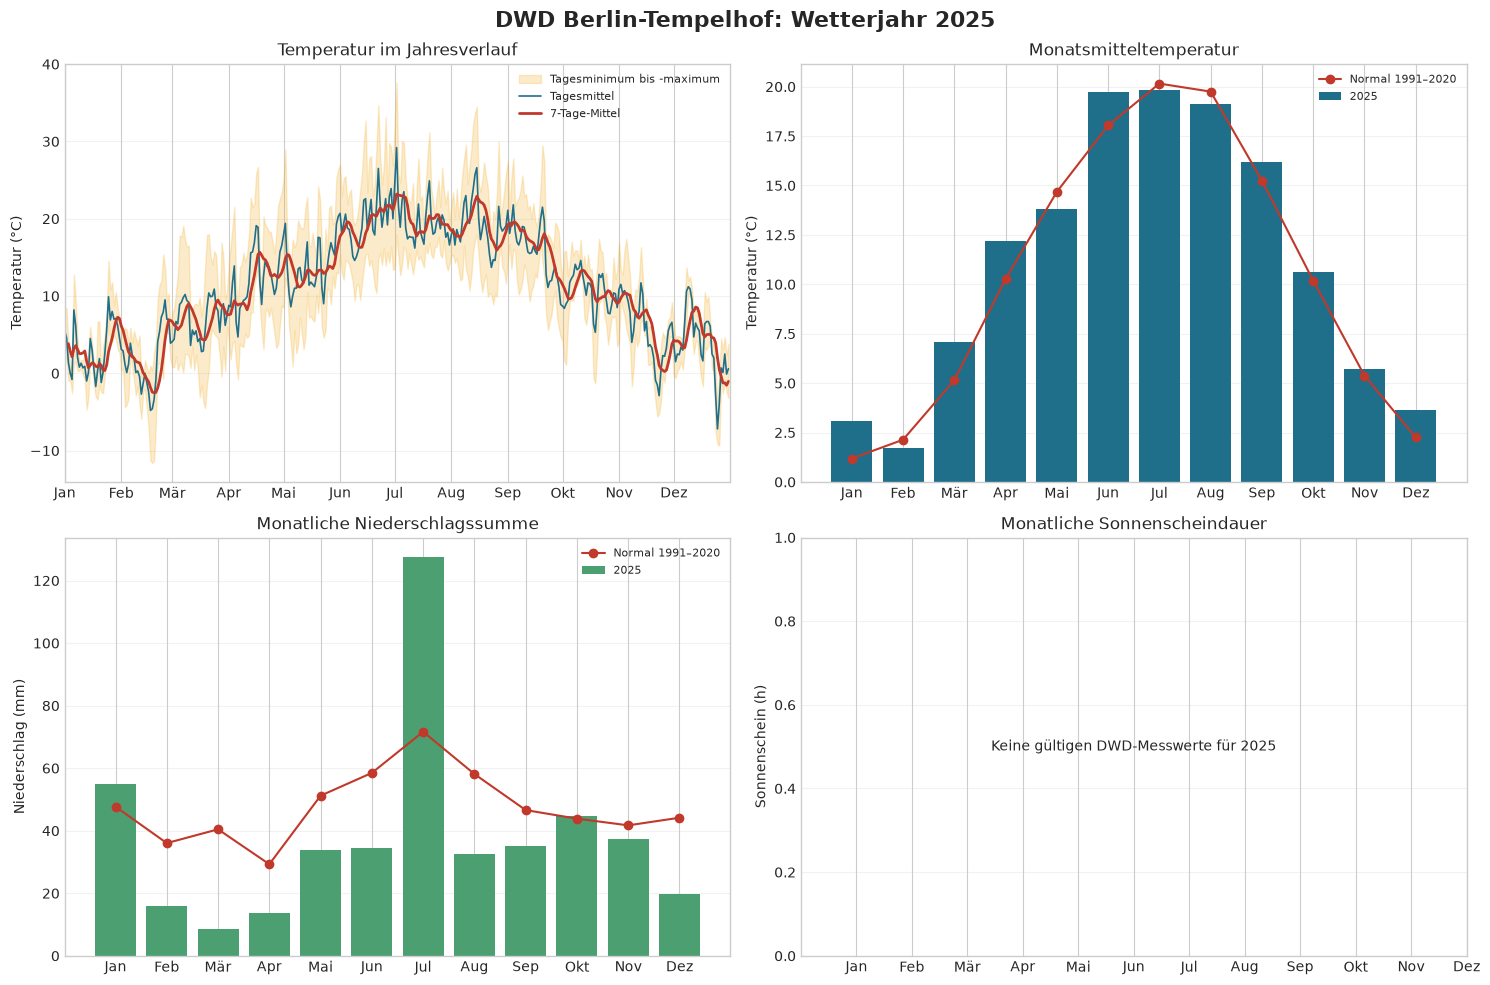

In [9]:
month_labels = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]
months = np.arange(1, 13)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(f"DWD Berlin-Tempelhof: Wetterjahr {YEAR}", fontsize=16, fontweight="bold")

ax = axes[0, 0]
valid_range = year_data["TNK"].notna() & year_data["TXK"].notna()
ax.fill_between(year_data.index, year_data["TNK"], year_data["TXK"], where=valid_range, color="#f3a712", alpha=0.22, label="Tagesminimum bis -maximum")
ax.plot(year_data.index, year_data["TMK"], color="#1f6f8b", linewidth=1.2, label="Tagesmittel")
ax.plot(year_data.index, year_data["TMK"].rolling(7, min_periods=3).mean(), color="#c0392b", linewidth=2, label="7-Tage-Mittel")
ax.set(title="Temperatur im Jahresverlauf", ylabel="Temperatur (°C)")
ax.set_xlim(pd.Timestamp(f"{YEAR}-01-01"), pd.Timestamp(f"{YEAR + 1}-01-01"))
ax.set_xticks(pd.date_range(f"{YEAR}-01-01", f"{YEAR}-12-01", freq="MS"))
ax.set_xticklabels(month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[0, 1]
ax.bar(months, monthly["TMK"], color="#1f6f8b", label="2025")
if not monthly_comparison.empty:
    ax.plot(months, monthly_comparison["TMK-Normal 1991–2020 (°C)"], color="#c0392b", marker="o", label="Normal 1991–2020")
ax.set(title="Monatsmitteltemperatur", ylabel="Temperatur (°C)", xticks=months, xticklabels=month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[1, 0]
ax.bar(months, monthly["RSK"], color="#4c9f70", label="2025")
if not monthly_comparison.empty:
    ax.plot(months, monthly_comparison["RSK-Normal 1991–2020 (mm)"], color="#c0392b", marker="o", label="Normal 1991–2020")
ax.set(title="Monatliche Niederschlagssumme", ylabel="Niederschlag (mm)", xticks=months, xticklabels=month_labels)
ax.legend(frameon=False, fontsize=8)

ax = axes[1, 1]
if monthly["SDK"].notna().any():
    ax.bar(months, monthly["SDK"], color="#f3a712")
else:
    ax.text(0.5, 0.5, "Keine gültigen DWD-Messwerte für 2025", ha="center", va="center", wrap=True, transform=ax.transAxes)
    ax.set_ylim(0, 1)
ax.set(title="Monatliche Sonnenscheindauer", ylabel="Sonnenschein (h)", xticks=months, xticklabels=month_labels)

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

In [10]:
def month_extreme(series, kind="max", unit=""):
    valid = series.dropna()
    if valid.empty:
        return "keine vollständigen Messwerte"
    month = valid.idxmax() if kind == "max" else valid.idxmin()
    return f"{month_labels[month - 1]} ({valid.loc[month]:.1f}{unit})"

findings = [
    f"**Temperatur:** Jahresmittel {year_data['TMK'].mean():.1f} °C; wärmster Monat {month_extreme(monthly['TMK'], 'max', ' °C')}, kältester Monat {month_extreme(monthly['TMK'], 'min', ' °C')}.",
    f"**Niederschlag:** {rain.sum(min_count=1):.1f} mm im Jahr; niederschlagsreichster Monat {month_extreme(monthly['RSK'], 'max', ' mm')} und {int((rain >= 1).sum())} Tage mit mindestens 1 mm.",
]

if sunshine.notna().any():
    findings.append(
        f"**Sonnenschein:** {sunshine.sum(min_count=1):.1f} Stunden im Jahr; "
        f"sonnenscheinreichster Monat {month_extreme(monthly['SDK'], 'max', ' h')}."
    )
else:
    findings.append("**Sonnenschein:** Für 2025 liegen in der DWD-Datei dieser Station keine gültigen SDK-Messwerte vor.")

if not monthly_comparison.empty and monthly_comparison["TMK-Abweichung (°C)"].notna().any():
    anomaly = monthly_comparison["TMK-Abweichung (°C)"].dropna()
    warmest_deviation = anomaly.idxmax()
    coolest_deviation = anomaly.idxmin()
    findings.append(
        f"**Referenzvergleich:** Größte positive Monatsabweichung beim Temperaturmittel im {month_labels[warmest_deviation - 1]} "
        f"({anomaly.loc[warmest_deviation]:+.1f} °C), größte negative im {month_labels[coolest_deviation - 1]} "
        f"({anomaly.loc[coolest_deviation]:+.1f} °C) gegenüber 1991–2020."
    )

findings.append(f"**Datenabdeckung:** Temperaturmittel an {int(year_data['TMK'].notna().sum())} von {len(expected_dates)} Tagen vorhanden.")
display(Markdown("## Kurzbefunde\n\n" + "\n\n".join(f"- {finding}" for finding in findings)))

## Kurzbefunde

- **Temperatur:** Jahresmittel 11.1 °C; wärmster Monat Jul (19.8 °C), kältester Monat Feb (1.7 °C).

- **Niederschlag:** 458.5 mm im Jahr; niederschlagsreichster Monat Jul (127.4 mm) und 97 Tage mit mindestens 1 mm.

- **Sonnenschein:** Für 2025 liegen in der DWD-Datei dieser Station keine gültigen SDK-Messwerte vor.

- **Referenzvergleich:** Größte positive Monatsabweichung beim Temperaturmittel im Mär (+2.0 °C), größte negative im Mai (-0.9 °C) gegenüber 1991–2020.

- **Datenabdeckung:** Temperaturmittel an 365 von 365 Tagen vorhanden.

## Modellvergleich: Training 2020–2024, Test 2025

Wie in einem Regression-/Classification-Learner werden mehrere Modellfamilien verglichen. Die Auswahl erfolgt chronologisch auf 2024 (Training 2020–2023); das ausgewählte Modell wird anschließend mit 2020–2024 neu trainiert und genau einmal gegen die Messwerte von 2025 getestet. Features sind Jahreszeit und die Messwerte des Vortags. Damit ist dies eine **rollierende Ein-Tages-Prognose**: Für jeden Testtag werden die tatsächlichen Wetterwerte des Vortags vorausgesetzt, nicht aber Messwerte desselben Tages. Sonnenschein (`SDK`) wird nicht modelliert, da laut obiger Datenprüfung für 2023–2025 keine Messwerte vorliegen.

Regression: Modellwahl anhand des MAE im Validierungsjahr 2024 (kleiner ist besser)


,Zielgröße,Modell,n Validierung,MAE 2024,RMSE 2024,R² 2024
12,Niederschlag (mm),Dummy (Mittelwert),366,2.093,3.874,-0.000
13,Niederschlag (mm),Ridge,366,2.096,3.879,-0.003
15,Niederschlag (mm),Gradient Boosting,366,2.186,3.951,-0.040
14,Niederschlag (mm),Random Forest,366,2.243,4.007,-0.070
7,Tagesmaximum (°C),Gradient Boosting,366,2.170,2.849,0.894
6,Tagesmaximum (°C),Random Forest,366,2.211,2.889,0.891
5,Tagesmaximum (°C),Ridge,366,2.240,2.892,0.891
4,Tagesmaximum (°C),Dummy (Mittelwert),366,7.564,8.806,-0.012
9,Tagesminimum (°C),Ridge,366,1.771,2.265,0.869
10,Tagesminimum (°C),Random Forest,366,1.780,2.249,0.871


Regression: unabhängiger Test gegen die tatsächlichen DWD-Messwerte 2025


,Ausgewähltes Modell,n Test,MAE 2025,RMSE 2025,R² 2025
Zielgröße,,,,,
Tagesmitteltemperatur (°C),Ridge,365,1.709,2.203,0.907
Tagesmaximum (°C),Gradient Boosting,365,2.281,2.958,0.877
Tagesminimum (°C),Ridge,365,1.698,2.169,0.887
Niederschlag (mm),Dummy (Mittelwert),365,1.873,2.873,-0.006


Klassifikation: Modellwahl anhand des F1-Scores im Validierungsjahr 2024


,Modell,n Validierung,Accuracy 2024,Precision 2024,Recall 2024,F1 2024,ROC-AUC 2024
1,Logistische Regression,366,0.648,0.392,0.571,0.465,0.652
2,Random Forest,366,0.713,0.453,0.347,0.393,0.618
3,Gradient Boosting,366,0.713,0.429,0.214,0.286,0.599
0,Dummy (Mehrheitsklasse),366,0.732,0.000,0.000,0.000,0.500


Klassifikation: unabhängiger Test 2025 (Regentag = mindestens 1 mm)


,Schwelle,n Test,Accuracy 2025,Precision 2025,Recall 2025,F1 2025,ROC-AUC 2025
Ausgewähltes Modell,,,,,,,
Logistische Regression,≥ 1.0 mm,365,0.647,0.364,0.443,0.4,0.636


,Prognose: kein Regentag,Prognose: Regentag
Ist: kein Regentag,193,75
Ist: Regentag,54,43


### Ergebnisinterpretation aus dem Testjahr 2025

- Die Temperaturmodelle werden anhand von MAE (mittlerer absoluter Fehler), RMSE (stärker gewichtete große Fehler) und R² verglichen. Der MAE beträgt 1.71 °C für TMK, 2.28 °C für TXK und 1.70 °C für TNK.

- Niederschlagsmenge: Dummy (Mittelwert) erreicht MAE 1.87 mm und R² -0.006. Das negative R² zeigt, dass die Vorhersagen beim quadratischen Fehler schlechter als der Mittelwert des Testjahres sind; eine belastbare Mengenprognose gelingt mit diesen Merkmalen nicht.

- Regentag-Klassifikation (mindestens 1.0 mm): F1 0.400, Precision 0.364, Recall 0.443 und ROC-AUC 0.636. Precision beschreibt den Anteil korrekter Regenwarnungen, Recall den Anteil erkannter Regentage.

- Das Testjahr 2025 wurde nicht zur Modellauswahl verwendet. Die Messwerte des Vortags sind als Eingabe erforderlich; daher bewertet der Test eine rollierende Tagesprognose und keine Vorhersage des gesamten Jahres im Voraus.

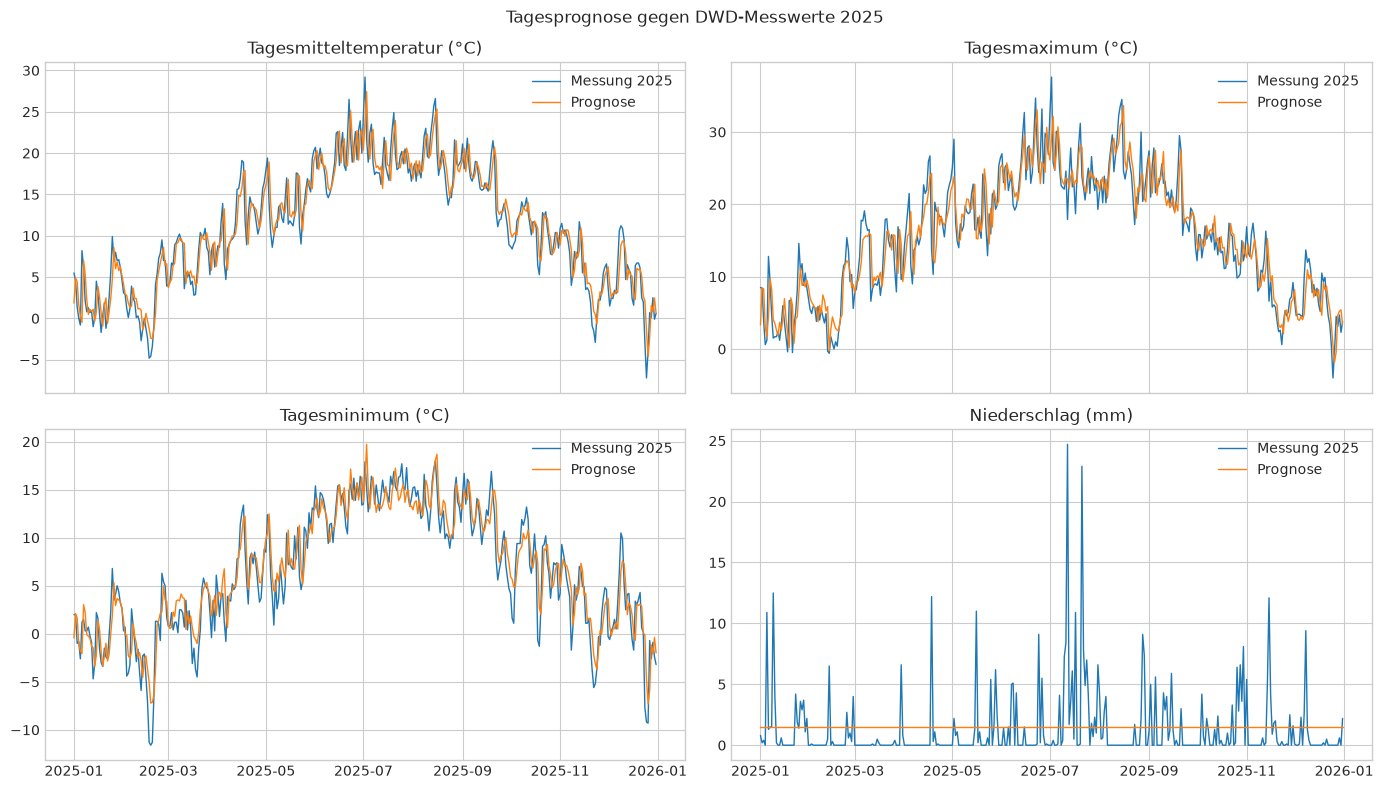

In [11]:
MODEL_COLUMNS = ["TMK", "TXK", "TNK", "RSK"]
REGRESSION_TARGETS = {
    "TMK": "Tagesmitteltemperatur (°C)",
    "TXK": "Tagesmaximum (°C)",
    "TNK": "Tagesminimum (°C)",
    "RSK": "Niederschlag (mm)",
}
RAIN_THRESHOLD_MM = 1.0

model_dates = pd.date_range("2020-01-01", "2025-12-31", freq="D", name="Datum")
model_weather = station_data.reindex(model_dates)[MODEL_COLUMNS].apply(pd.to_numeric, errors="coerce")
day_of_year = model_weather.index.day_of_year.to_numpy()
day_of_week = model_weather.index.day_of_week.to_numpy()
X = pd.DataFrame({
    "jahreszeit_sin": np.sin(2 * np.pi * (day_of_year - 1) / 365.25),
    "jahreszeit_cos": np.cos(2 * np.pi * (day_of_year - 1) / 365.25),
    "wochentag_sin": np.sin(2 * np.pi * day_of_week / 7),
    "wochentag_cos": np.cos(2 * np.pi * day_of_week / 7),
}, index=model_weather.index)
for column in MODEL_COLUMNS:
    X[f"{column}_Vortag"] = model_weather[column].shift(1)

year = X.index.year
validation_train_mask = (year >= 2020) & (year <= 2023)
validation_mask = year == 2024
final_train_mask = (year >= 2020) & (year <= 2024)
test_mask = year == 2025

def regression_models():
    return {
        "Dummy (Mittelwert)": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", DummyRegressor(strategy="mean"))]),
        "Ridge": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler()), ("model", Ridge(alpha=10.0))]),
        "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", HistGradientBoostingRegressor(max_iter=150, learning_rate=0.06, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=42))]),
    }

def classification_models():
    return {
        "Dummy (Mehrheitsklasse)": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", DummyClassifier(strategy="most_frequent"))]),
        "Logistische Regression": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))]),
        "Random Forest": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample", random_state=42, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("model", HistGradientBoostingClassifier(max_iter=150, learning_rate=0.06, max_leaf_nodes=15, l2_regularization=1.0, early_stopping=False, random_state=42))]),
    }

regression_validation_rows = []
regression_test_rows = []
regression_predictions = pd.DataFrame(index=model_weather.index[test_mask])
for target, label in REGRESSION_TARGETS.items():
    y = model_weather[target]
    train_rows = validation_train_mask & y.notna().to_numpy()
    validation_rows = validation_mask & y.notna().to_numpy()
    test_rows = test_mask & y.notna().to_numpy()
    if not train_rows.any() or not validation_rows.any() or not test_rows.any():
        raise ValueError(f"Zu wenige Messwerte für Training, Validierung oder Test bei {target}.")

    validation_mae = {}
    for model_name, model in regression_models().items():
        model.fit(X.loc[train_rows], y.loc[train_rows])
        prediction = model.predict(X.loc[validation_rows])
        regression_validation_rows.append({
            "Zielgröße": label,
            "Modell": model_name,
            "n Validierung": int(validation_rows.sum()),
            "MAE 2024": mean_absolute_error(y.loc[validation_rows], prediction),
            "RMSE 2024": np.sqrt(mean_squared_error(y.loc[validation_rows], prediction)),
            "R² 2024": r2_score(y.loc[validation_rows], prediction),
        })
        validation_mae[model_name] = regression_validation_rows[-1]["MAE 2024"]

    best_name = min(validation_mae, key=validation_mae.get)
    final_model = regression_models()[best_name]
    final_rows = final_train_mask & y.notna().to_numpy()
    final_model.fit(X.loc[final_rows], y.loc[final_rows])
    prediction = final_model.predict(X.loc[test_rows])
    regression_predictions.loc[y.index[test_rows], f"{target}_Ist"] = y.loc[test_rows]
    regression_predictions.loc[y.index[test_rows], f"{target}_Prognose"] = prediction
    regression_test_rows.append({
        "Zielgröße": label,
        "Ausgewähltes Modell": best_name,
        "n Test": int(test_rows.sum()),
        "MAE 2025": mean_absolute_error(y.loc[test_rows], prediction),
        "RMSE 2025": np.sqrt(mean_squared_error(y.loc[test_rows], prediction)),
        "R² 2025": r2_score(y.loc[test_rows], prediction),
    })

regression_validation = pd.DataFrame(regression_validation_rows).sort_values(["Zielgröße", "MAE 2024"])
regression_test_metrics = pd.DataFrame(regression_test_rows).set_index("Zielgröße")
print("Regression: Modellwahl anhand des MAE im Validierungsjahr 2024 (kleiner ist besser)")
display(regression_validation.round(3))
print("Regression: unabhängiger Test gegen die tatsächlichen DWD-Messwerte 2025")
display(regression_test_metrics.round(3))

rain_target = model_weather["RSK"].ge(RAIN_THRESHOLD_MM).where(model_weather["RSK"].notna())
classification_train_rows = validation_train_mask & rain_target.notna().to_numpy()
classification_validation_rows = validation_mask & rain_target.notna().to_numpy()
classification_test_rows = test_mask & rain_target.notna().to_numpy()
if rain_target.loc[classification_train_rows].nunique() != 2 or rain_target.loc[classification_validation_rows].nunique() != 2:
    raise ValueError("Für die Regen-Klassifikation müssen beide Klassen im Training und im Validierungsjahr vorkommen.")

classification_validation_rows_out = []
y_validation = rain_target.loc[classification_validation_rows].astype(int)
for model_name, model in classification_models().items():
    model.fit(X.loc[classification_train_rows], rain_target.loc[classification_train_rows].astype(int))
    prediction = model.predict(X.loc[classification_validation_rows])
    probability = model.predict_proba(X.loc[classification_validation_rows])[:, 1]
    classification_validation_rows_out.append({
        "Modell": model_name,
        "n Validierung": len(y_validation),
        "Accuracy 2024": accuracy_score(y_validation, prediction),
        "Precision 2024": precision_score(y_validation, prediction, zero_division=0),
        "Recall 2024": recall_score(y_validation, prediction, zero_division=0),
        "F1 2024": f1_score(y_validation, prediction, zero_division=0),
        "ROC-AUC 2024": roc_auc_score(y_validation, probability),
    })

classification_validation = pd.DataFrame(classification_validation_rows_out).sort_values("F1 2024", ascending=False)
best_classifier_name = classification_validation.iloc[0]["Modell"]
final_classifier = classification_models()[best_classifier_name]
final_classifier.fit(X.loc[final_train_mask & rain_target.notna().to_numpy()], rain_target.loc[final_train_mask & rain_target.notna().to_numpy()].astype(int))
y_test = rain_target.loc[classification_test_rows].astype(int)
rain_prediction = final_classifier.predict(X.loc[classification_test_rows])
rain_probability = final_classifier.predict_proba(X.loc[classification_test_rows])[:, 1]
classification_test_metrics = pd.DataFrame([{
    "Ausgewähltes Modell": best_classifier_name,
    "Schwelle": f"≥ {RAIN_THRESHOLD_MM:.1f} mm",
    "n Test": len(y_test),
    "Accuracy 2025": accuracy_score(y_test, rain_prediction),
    "Precision 2025": precision_score(y_test, rain_prediction, zero_division=0),
    "Recall 2025": recall_score(y_test, rain_prediction, zero_division=0),
    "F1 2025": f1_score(y_test, rain_prediction, zero_division=0),
    "ROC-AUC 2025": roc_auc_score(y_test, rain_probability) if y_test.nunique() == 2 else np.nan,
}]).set_index("Ausgewähltes Modell")
print("Klassifikation: Modellwahl anhand des F1-Scores im Validierungsjahr 2024")
display(classification_validation.round(3))
print("Klassifikation: unabhängiger Test 2025 (Regentag = mindestens 1 mm)")
display(classification_test_metrics.round(3))
rain_confusion = confusion_matrix(y_test, rain_prediction, labels=[0, 1])
display(pd.DataFrame(rain_confusion, index=["Ist: kein Regentag", "Ist: Regentag"], columns=["Prognose: kein Regentag", "Prognose: Regentag"]))

temperature_targets = ["TMK", "TXK", "TNK"]
temperature_mae = regression_test_metrics.loc[
    [REGRESSION_TARGETS[target] for target in temperature_targets], "MAE 2025"
]
rain_regression = regression_test_metrics.loc[REGRESSION_TARGETS["RSK"]]
rain_classification = classification_test_metrics.iloc[0]
interpretation = [
    "### Ergebnisinterpretation aus dem Testjahr 2025",
    "- Die Temperaturmodelle werden anhand von MAE (mittlerer absoluter Fehler), RMSE (stärker gewichtete große Fehler) und R² verglichen. "
    f"Der MAE beträgt {temperature_mae.loc[REGRESSION_TARGETS['TMK']]:.2f} °C für TMK, "
    f"{temperature_mae.loc[REGRESSION_TARGETS['TXK']]:.2f} °C für TXK und "
    f"{temperature_mae.loc[REGRESSION_TARGETS['TNK']]:.2f} °C für TNK.",
    f"- Niederschlagsmenge: {rain_regression['Ausgewähltes Modell']} erreicht MAE "
    f"{rain_regression['MAE 2025']:.2f} mm und R² {rain_regression['R² 2025']:.3f}. "
    + ("Das negative R² zeigt, dass die Vorhersagen beim quadratischen Fehler schlechter als der Mittelwert des Testjahres sind; eine belastbare Mengenprognose gelingt mit diesen Merkmalen nicht."
       if rain_regression["R² 2025"] < 0 else "Das R² ist positiv und zeigt gegenüber dem Testjahresmittel eine erklärende Leistung."),
    f"- Regentag-Klassifikation (mindestens {RAIN_THRESHOLD_MM:.1f} mm): F1 {rain_classification['F1 2025']:.3f}, "
    f"Precision {rain_classification['Precision 2025']:.3f}, Recall {rain_classification['Recall 2025']:.3f} "
    f"und ROC-AUC {rain_classification['ROC-AUC 2025']:.3f}. Precision beschreibt den Anteil korrekter Regenwarnungen, "
    "Recall den Anteil erkannter Regentage.",
    "- Das Testjahr 2025 wurde nicht zur Modellauswahl verwendet. Die Messwerte des Vortags sind als Eingabe erforderlich; "
    "daher bewertet der Test eine rollierende Tagesprognose und keine Vorhersage des gesamten Jahres im Voraus.",
]
display(Markdown("\n\n".join(interpretation)))

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (target, label) in zip(axes.flat, REGRESSION_TARGETS.items()):
    observed = regression_predictions[f"{target}_Ist"]
    predicted = regression_predictions[f"{target}_Prognose"]
    ax.plot(observed.index, observed, label="Messung 2025", linewidth=1)
    ax.plot(predicted.index, predicted, label="Prognose", linewidth=1)
    ax.set_title(label)
    ax.legend()
fig.suptitle("Tagesprognose gegen DWD-Messwerte 2025")
fig.tight_layout()
plt.show()

## Grenzen der Auswertung und nächste Schritte

- Eine DWD-Station bildet lokale Unterschiede innerhalb Berlins nur eingeschränkt ab.
- Niederschlag und Sonnenschein können stations- und messbedingt fehlende Werte enthalten; die Abdeckung steht oben und fehlende Werte werden nicht als Null interpretiert.
- Der Vergleich 1991–2020 ist eine Monatsreferenz derselben Station. Er ersetzt keine offizielle Gebietsmittel-Auswertung und belegt für sich genommen keinen Klimatrend.
- Die Modellwahl nutzt 2024 als chronologisches Validierungsjahr; die ausgewählten Modelle werden anschließend auf 2020–2024 neu trainiert. 2025 bleibt der unabhängige Test.
- Es handelt sich um eine rollierende Ein-Tages-Prognose mit bekannten Wetter-Messwerten des Vortags. Eine Prognose über viele Tage im Voraus würde ein anderes Versuchsdesign und zusätzliche Prognosehorizonte erfordern.
- Fehlende Eingangswerte werden innerhalb der Modell-Pipelines mit dem Trainingsmedian imputiert; Zielwerte mit fehlenden DWD-Messungen werden für die jeweilige Kennzahl ausgelassen. Sonnenschein (`SDK`) wird wegen fehlender Messungen in 2023–2025 nicht modelliert.
- Niederschlagsmenge ist stark schwankend und schwer vorherzusagen. Ein negatives R² weist darauf hin, dass das Modell im quadratischen Fehler schlechter als der Mittelwert des Testjahres abschneidet; Kennzahlen sind daher zusammen mit der Baseline und der Datenabdeckung zu bewerten.

Die Originalarchive liegen nach dem ersten erfolgreichen Download im Ordner `data/`. Zum erneuten Laden können sie dort gelöscht werden; beim nächsten Durchlauf lädt das Notebook die DWD-Dateien erneut.